In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 


In [2]:
df = pd.read_csv('../data/retail_sales_dataset.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
df.shape


(1000, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [5]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['Date'].head()

0    2023-11-24
1    2023-02-27
2    2023-01-13
3    2023-05-21
4    2023-05-06
Name: Date, dtype: str

In [8]:
df["Date"] = pd.to_datetime(df["Date"])

In [9]:
df["Date"].dtype

dtype('<M8[us]')

In [10]:
df[["Quantity","Price per Unit","Total Amount"]].head()

,Quantity,Price per Unit,Total Amount
0,3,50,150
1,2,500,1000
2,1,30,30
3,1,500,500
4,2,50,100


In [11]:
df["Quantity"] * df["Price per Unit"] == df["Total Amount"]

0      True
1      True
2      True
3      True
4      True
       ... 
995    True
996    True
997    True
998    True
999    True
Length: 1000, dtype: bool

In [12]:
## muje date_time se month nikalna hai so..

df["Month"]=df["Date"].dt.month_name()

In [13]:
df[["Date","Month"]]

,Date,Month
0,2023-11-24,November
1,2023-02-27,February
2,2023-01-13,January
3,2023-05-21,May
4,2023-05-06,May
...,...,...
995,2023-05-16,May
996,2023-11-17,November
997,2023-10-29,October
998,2023-12-05,December


In [14]:
## Year check karne ke lliye ..
df["Date"].dt.year.unique()

## 



array([2023, 2024], dtype=int32)

In [15]:
df["Year"]= df["Date"].dt.year

In [16]:
df[["Date","Year","Month","Total Amount"]].head()

,Date,Year,Month,Total Amount
0,2023-11-24,2023,November,150
1,2023-02-27,2023,February,1000
2,2023-01-13,2023,January,30
3,2023-05-21,2023,May,500
4,2023-05-06,2023,May,100


In [17]:
## HAR month ki total sales calculate ..

df.groupby(["Year","Month"])["Total Amount"].sum()



Year  Month    
2023  April        33870
      August       36960
      December     44690
      February     44060
      January      35450
      July         35465
      June         36715
      March        28990
      May          53150
      November     34920
      October      46580
      September    23620
2024  January       1530
Name: Total Amount, dtype: int64

In [18]:
# df["Year"].value_counts().sort_index()

# df[df["Year"]==2024]

# df["Month"]=df["Date"].dt.month_name()

# df[df["Year"] == 2024][["Date", "Month", "Year", "Total Amount"]]


##       task... highest sales in month




In [19]:
monthly_sales = df.groupby(["Year", "Month"])["Total Amount"].sum()
monthly_sales.max()
monthly_sales.min()


np.int64(1530)

In [20]:
monthly_sales.idxmax()
monthly_sales.idxmin()

(np.int32(2024), 'January')

In [21]:
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Year
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,November,2023
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,February,2023
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,January,2023
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,May,2023
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,May,2023
...,...,...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50,May,2023
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90,November,2023
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100,October,2023
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150,December,2023


In [22]:
df["Total Amount"].sum()

np.int64(456000)

In [23]:
## Total Qunatity 

total_quantity = df["Quantity"].sum()
total_quantity

np.int64(2514)

In [24]:
# Total transaction ID

total_transaction = df["Transaction ID"].count()
total_transaction
# trans = df["Transaction ID"].nunique()
# trans

np.int64(1000)

In [25]:
## UNIQ CUSTO... IDS
uniqe_cust = df["Customer ID"].nunique()
uniqe_cust

1000

In [26]:
## Total amount ka (mean , median , minimum, maximum)

#1 calculate avarage transaction amont
avg_tra_amt = df["Total Amount"].mean()
avg_tra_amt    ## 456

#2 median
mid = df["Total Amount"].median()
mid         ## 135

#3 minimum
m = df["Total Amount"].min()
m       #25

#4 maximum
m2= df["Total Amount"].max()
m2     #2000




np.int64(2000)

In [27]:

print(df.shape)
print(df["Total Amount"].sum())
print(df["Total Amount"].count())

(1000, 11)
456000
1000


In [28]:
## Analyse sales by product category..

product_cat = df.groupby(["Product Category"])["Total Amount"].sum()
product_cat

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [29]:
### Gender wise sales Analysis..
ana_sales_by_gen = df.groupby(["Gender"])["Total Amount"].sum()
ana_sales_by_gen

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [30]:
## Age analyse 

avg_age = df["Age"].mean()
avg_age

## min..
min_age = df["Age"].min()
min_age   ##18

## max..
max_age = df["Age"].max()
max_age    ##64

### Age groups define 

age_groups = pd.cut(
    df["Age"],bins=[17,25,35,45,55,65],labels=["18-25","26-35","36-45","46-55","56-64"]
)
age_groups.value_counts().sort_index()




Age
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64

In [31]:
###  Compare quantity sold across product categories

quantity_procat = df.groupby(["Product Category"])["Quantity"].sum()
quantity_procat

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64

In [32]:
# monthly_sales = df.groupby(["Year", "Month"])["Total Amount"].sum()
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()
monthly_sales 

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [33]:
# df_2023 = df[(df["Year"]==2023) & (df["Gender"]=="Male")]
# df_2023
df_2023 = df[(df["Year"]==2023) & (df["Gender"]=="Female")]
df_2023

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Year
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,February,2023
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30,April,2023
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200,October,2023
14,15,2023-01-16,CUST015,Female,42,Electronics,4,500,2000,January,2023
16,17,2023-04-22,CUST017,Female,27,Clothing,4,25,100,April,2023
...,...,...,...,...,...,...,...,...,...,...,...
992,993,2023-02-06,CUST993,Female,48,Electronics,3,50,150,February,2023
993,994,2023-12-18,CUST994,Female,51,Beauty,2,500,1000,December,2023
994,995,2023-04-30,CUST995,Female,41,Clothing,1,30,30,April,2023
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100,October,2023


In [34]:
yearly_sales = df.groupby(["Year"])["Total Amount"].sum()
yearly_sales

df["Year"].value_counts().sort_index()

Year
2023    998
2024      2
Name: count, dtype: int64

In [35]:
## har month me kis product ki kitni sales hui ...

analys_month_product_sales = df.groupby(
["Product Category",
df["Date"].dt.to_period("M")])["Total Amount"].sum()
analys_month_product_sales

Product Category  Date   
Beauty            2023-01    12430
                  2023-02    14035
                  2023-03    10545
                  2023-04    11905
                  2023-05    12450
                  2023-06    10995
                  2023-07    16090
                  2023-08     9790
                  2023-09     6320
                  2023-10    15355
                  2023-11     9700
                  2023-12    12400
                  2024-01     1500
Clothing          2023-01    13125
                  2023-02    14560
                  2023-03    15065
                  2023-04    13940
                  2023-05    17455
                  2023-06    10170
                  2023-07     8250
                  2023-08    12455
                  2023-09     9975
                  2023-10    13315
                  2023-11    15200
                  2023-12    12070
Electronics       2023-01     9895
                  2023-02    15465
                  2023-03    

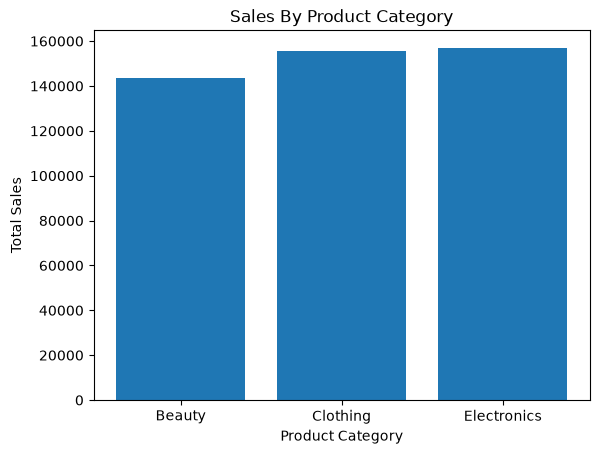

In [48]:
### Product cat... ka bar chart 
# product_cat = df.groupby(["Product Category"])["Total Amount"].sum()
# product_cat

plt.bar(product_cat.index,product_cat.values)
plt.title("Sales By Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.savefig("../charts/Sales_by_product_category.png",
            bbox_inches="tight",dpi=300)
plt.show()

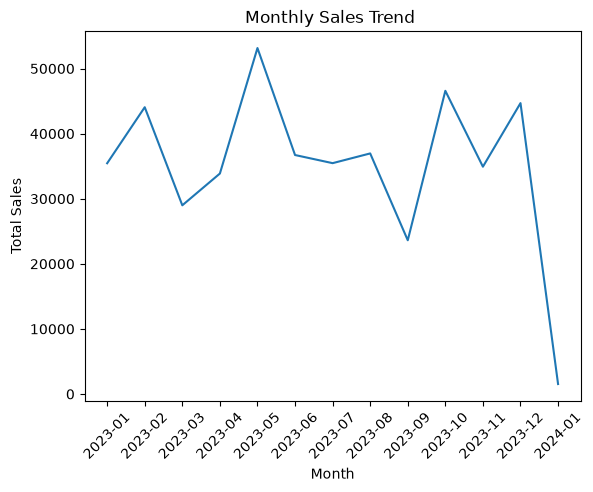

In [49]:
## Monthly sales kese badi ya gati 

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)
plt.title("Monthly Sales Trend ")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.savefig("../charts/Monthly_Sales_Trend.png",
            bbox_inches="tight",dpi=300)
plt.show()


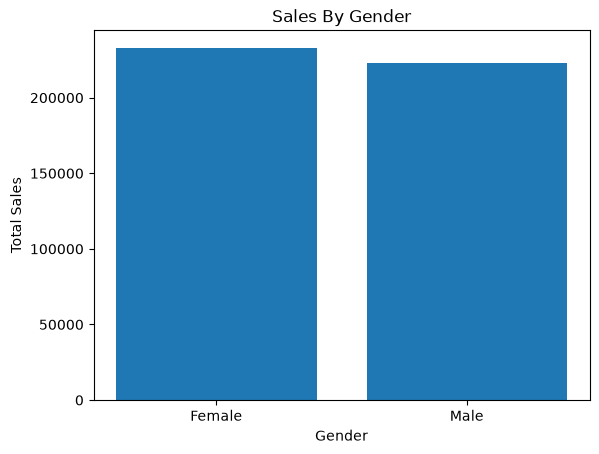

In [50]:
## Gender Wise Sales analyse... 

plt.bar(ana_sales_by_gen.index,ana_sales_by_gen.values)
plt.title("Sales By Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.savefig("../charts/Sales_By_Gender.png",
            bbox_inches="tight",dpi=300)
plt.show()

## Observation: Female customers ki sales ₹2,32,840 aur Male customers ki sales ₹2,23,160 hai.
## Insight: Female customers ki sales, Male customers se ₹9,680 zyada hai.

In [39]:
## Gender + Product Category Analysis

gender_categoy_sales = df.groupby(["Gender","Product Category"])["Total Amount"].sum()
gender_categoy_sales




Gender  Product Category
Female  Beauty              74830
        Clothing            81275
        Electronics         76735
Male    Beauty              68685
        Clothing            74305
        Electronics         80170
Name: Total Amount, dtype: int64

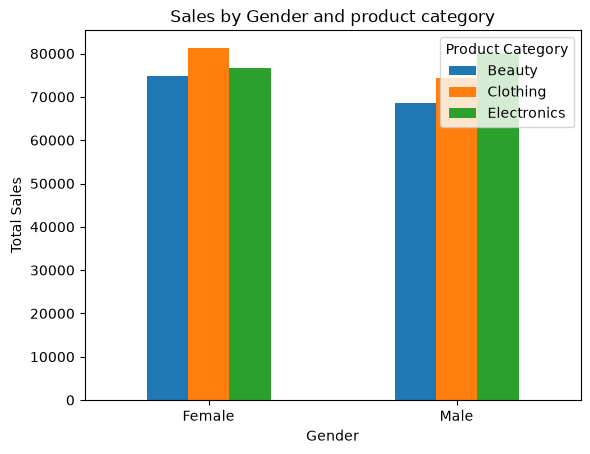

In [51]:
#### Bar chart

gender_categoy_sales.unstack().plot(kind="bar")
plt.title("Sales by Gender and product category")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.savefig("../charts/Sales_By_Gender_And_Product_Category.png",
            bbox_inches="tight",dpi=300)
plt.show()

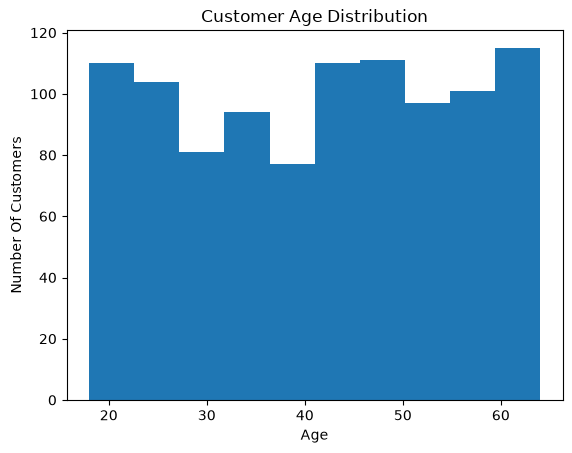

In [52]:
## ☐  Create a histogram for transaction amounts or customer ages

plt.hist(df["Age"],bins=10)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number Of Customers")
plt.savefig("../charts/Customer_Age_Distribution.png",
            bbox_inches="tight",dpi=300)
plt.show()


# Observation: Kis age range mein customers sabse zyada hain?
# Business Insight: Customer age distribution se business ko kya samajh aata hai?
# Recommendation: Business ko customers ki age ke basis par kya strategy consider karni chahiye?

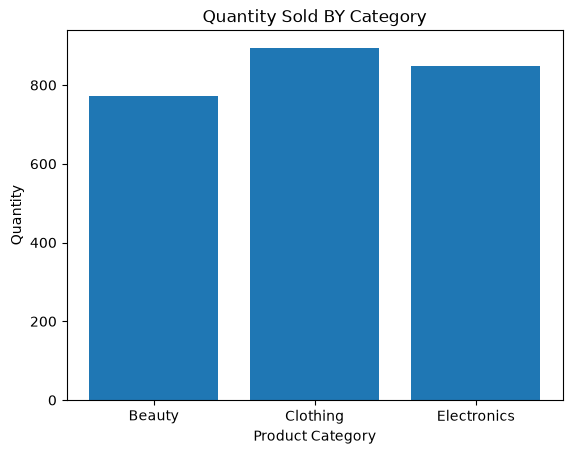

In [53]:
## Create a chart comparing quantity sold by category
# quantity_procat 

plt.bar(quantity_procat.index,quantity_procat.values)
plt.title("Quantity Sold BY Category")
plt.xlabel(" Product Category ")
plt.ylabel("Quantity")
plt.savefig("../charts/Quantity_Sold_By_Category.png",
            bbox_inches="tight",dpi=300)
plt.show()



###Task 4 — Har Chart ki Explanation
# Har chart ke neeche notebook ke Markdown cell mein likhna:
# - Observation: Chart mein kya dikh raha hai?
# - Insight: Is result ka kya matlab hai?
# - Recommendation: Business is information ka kya use kar sakta hai?

In [43]:
# ## Business Insights and Observations

# ### 1. Sales by Product Category

# **Observation:** Electronics ki sales sabse zyada ₹1,56,905 hai, jabki Beauty ki sabse kam ₹1,43,515 hai.

# **Business Insight:** Electronics category total sales mein sabse bada contribution deti hai.

# **Recommendation:** Business Electronics ki demand aur stock availability monitor kar sakta hai.

# ### 2. Sales by Gender

# **Observation:** Female customers ki total sales ₹2,32,840 hai aur Male customers ki ₹2,23,160 hai.

# **Business Insight:** Dataset mein Female customers ki total sales Male customers se ₹9,680 zyada hai.

# **Recommendation:** Business gender-wise product preferences analyze karke relevant promotions plan kar sakta hai.

# ### 3. Quantity Sold by Category

# **Observation:** Clothing ki quantity sabse zyada 894 units hai, jabki Beauty ki 771 units hai.

# **Business Insight:** Clothing category mein sabse zyada units sell hui hain.

# **Recommendation:** Business Clothing ki demand aur inventory ko monitor kar sakta hai.

# ### 4. Monthly Sales Trend

# **Observation:** May 2023 mein sales sabse zyada ₹53,150 thi. January 2024 mein sirf 2 records hain.

# **Business Insight:** May 2023 dataset ka highest-sales month hai. January 2024 ka data poore month ki performance represent nahi karta.

# **Recommendation:** Business monthly sales trends monitor karke seasonal patterns identify kar sakta hai.

In [44]:
product_cat

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

### Final Conclusion

In [45]:
## Final Conclusion

# This Retail Sales Analysis project was performed using Python, Pandas, Matplotlib, and a retail sales dataset containing 1,000 records.

# The dataset generated total sales of ₹4,56,000, with 2,514 units sold across three product categories.

# Electronics recorded the highest sales of ₹1,56,905, while Clothing had the highest quantity sold at 894 units. Female customers contributed ₹2,32,840 in sales, compared to ₹2,23,160 from Male customers. May 2023 was the highest-sales month, with ₹53,150 in sales.

# This analysis helps identify sales patterns, category performance, customer demographics, and monthly trends. Based on these findings, the business can monitor product demand, improve inventory planning, and analyze customer purchasing patterns to support better business decisions.

# **Tools Used:** Python, Pandas, Matplotlib, Jupyter Notebook.

In [46]:
df.to_csv("../data/retail_sales_cleaned.csv",index=False)

In [47]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Month', 'Year'],
      dtype='str')